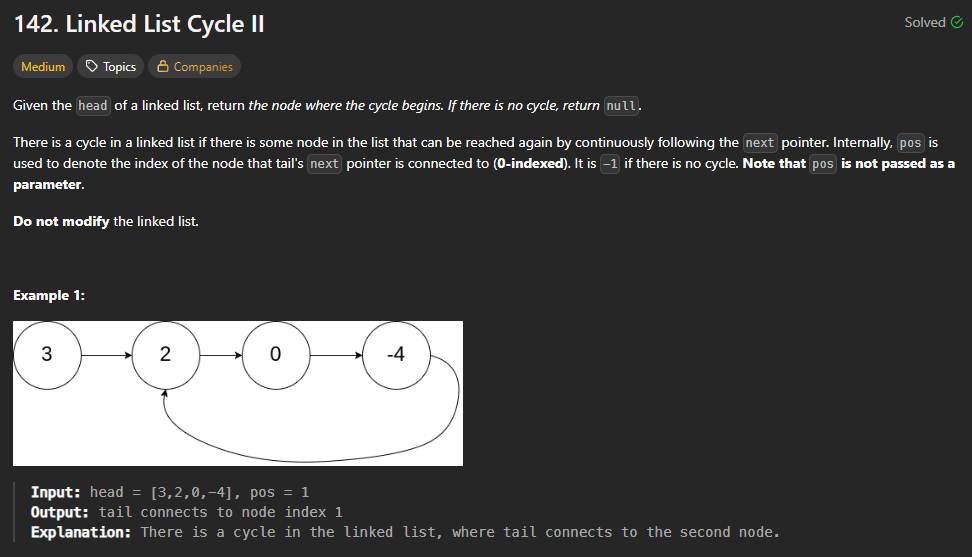

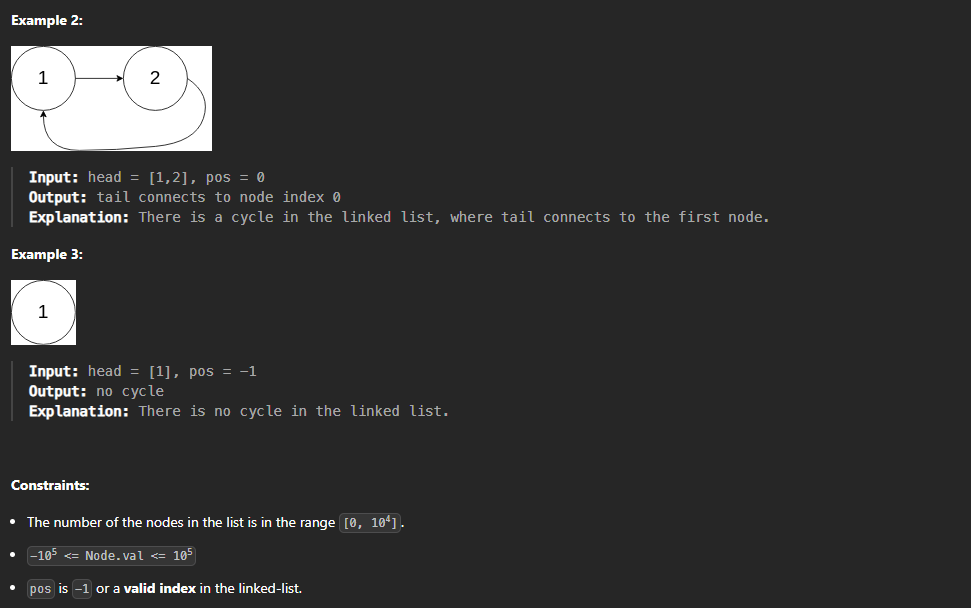

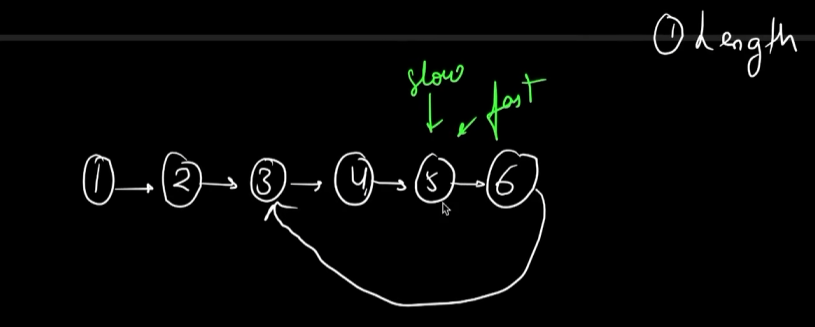

In [3]:
class ListNode:
  def __init__(self, val=0, next=None):
    self.val = val
    self.next = next

class Solution:
  def linkedListHelper(self, arr, pos=-1):
    if not arr:
      return None

    head = ListNode(arr[0])
    curr = head
    cycle_node = None

    if pos == 0:
      cycle_node = head

    for i, val in enumerate(arr[1:], start=1):
      curr.next = ListNode(val)
      curr = curr.next
      if i == pos:
        cycle_node = curr

    if pos != -1 and cycle_node is not None:
      curr.next = cycle_node

    return head

  def detectCycle(self, head: ListNode | None) -> ListNode | None:
    # phase 1: detect if cycle present or not
    slow = head
    fast = head
    hasCycle = False

    while fast != None and fast.next != None:
      slow = slow.next
      fast = fast.next.next

      if slow == fast:
        hasCycle = True
        break

    if not hasCycle:
      return None

    # phase 2: if cycle present, then first I find length of cycle
    l = 0
    while slow.next != fast:
      l = l + 1
      slow = slow.next

    l = l + 1  # this is basically the length of our cycle

    # resetting my pointers
    slow = head
    fast = head

    # iterating my fast pointer to next till cycle length
    for i in range(l):
      fast = fast.next

    # now moving both slow & fast pointer until they become same
    while slow != fast:
      slow = slow.next
      fast = fast.next

    return slow  # this is our node where the cycle actually begins


# Real test case execution:
s = Solution()

# Create a list [3, 2, 0, -4] where tail points to index 1 (value 2)
head_with_cycle = s.linkedListHelper([3, 2, 0, -4], pos=1)
cycle_start_node = s.detectCycle(head_with_cycle)

if cycle_start_node:
    print(f"Cycle detected at node with value: {cycle_start_node.val}")
else:
    print("No cycle detected.")

Cycle detected at node with value: 2
